# Indian Paint Industry: Deep Learning Revenue Forecasting with PyTorch

## Objective & Neural Architecture Design
In this notebook, we design, train, and evaluate a deep neural network in **PyTorch** to predict future quarterly revenue of Indian paint companies.

### Architectural Specifications:
As required for deep tabular financial regression:
1. **Network Depth**: Deep Multi-Layer Perceptron (MLP) with **at least 4 hidden layers**:
   - `Input -> Linear(128) -> BatchNorm1d -> ReLU -> Dropout(0.15)`
   - `Linear(64) -> BatchNorm1d -> ReLU -> Dropout(0.15)`
   - `Linear(32) -> BatchNorm1d -> ReLU -> Dropout(0.15)`
   - `Linear(16) -> BatchNorm1d -> ReLU -> Dropout(0.15)`
   - `Linear(1) -> Output (Predicted Revenue)`
2. **Weight Initialization**: **He (Kaiming Normal) Initialization** (`nn.init.kaiming_normal_`), specifically tailored to maintain variance and avoid vanishing/exploding gradients with ReLU activations.
3. **Batch Normalization**: `nn.BatchNorm1d` applied after each linear layer to normalize internal feature scale distributions across training mini-batches.
4. **Hardware Acceleration**: Automatic device detection:
   - Apple Silicon GPU via Metal Performance Shaders (`torch.device("mps")`)
   - NVIDIA GPU via CUDA (`torch.device("cuda")`)
   - Fallback to optimized CPU.
5. **Loss & Optimizer**:
   - Huber Loss (`nn.SmoothL1Loss`): Combines MSE efficiency with MAE robustness to large financial shocks (e.g. COVID quarters).
   - Optimizer: `AdamW` with weight decay for $L_2$ weight regularization.
   - Scheduler: `ReduceLROnPlateau` reducing learning rate on validation loss plateaus.
   - Early Stopping: Restores the best checkpoint when validation loss ceases improving.

In [1]:
# Boilerplate Imports & Hardware Detection
%matplotlib inline
import sys
from pathlib import Path

project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
if str(project_root.parent) not in sys.path:
    sys.path.append(str(project_root.parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import warnings
warnings.filterwarnings('ignore')

import src

# Check hardware acceleration
device = src.get_device()
print(f"PyTorch Version: {torch.__version__}")
print(f"Active Compute Device: {device}")
if device.type == 'mps':
    print("Apple Silicon Metal Performance Shaders (MPS) GPU acceleration ENABLED!")

PyTorch Version: 2.14.1
Active Compute Device: mps
Apple Silicon Metal Performance Shaders (MPS) GPU acceleration ENABLED!


## 1. Inspecting the Deep Neural Network Architecture
Let's instantiate `DeepFinancialMLP` with 4 hidden layers, He initialization, and Batch Normalization, and inspect its parameters.

In [2]:
# Instantiate sample model to inspect layers
sample_model = src.DeepFinancialMLP(input_dim=21, hidden_dims=[128, 64, 32, 16], dropout_rate=0.15)
print(sample_model)

total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

DeepFinancialMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.15, inplace=False)
    (12): Linear(in_features=32, out_features=16, bias=True)
    (13): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.15, inplace=False)
    (16): Linear(in_features=16, out_features=1, bias=True)
  )
)

Total Trainable P

## 2. Quarterly Data Ingestion & Feature Engineering
We ingest quarterly standalone financials and generate the seasonal and operational feature set.

In [3]:
df_quarterly = src.load_merged_quarterly(basis="Standalone")
df_qtr_feat = src.build_quarterly_features(df_quarterly, target_col="target_next_revenue", forecast_horizon=1)

qtr_feature_cols = [
    'revenue', 'raw_material_ratio', 'ebitda_margin', 'net_margin', 'revenue_growth',
    'revenue_lag1', 'revenue_lag2', 'revenue_lag4', 'ebitda_lag1', 'ebitda_lag4',
    'revenue_qoq_growth', 'rolling_mean_4q', 'rolling_std_4q',
    'quarter_Q1', 'quarter_Q2', 'quarter_Q3', 'quarter_Q4'
]

X_qtr, y_qtr, clean_qtr, all_qtr_cols = src.prepare_feature_matrix(
    df_qtr_feat, feature_cols=qtr_feature_cols, target_col="target_next_revenue", include_company_dummies=True
)

print(f"Input Feature Dimension: {X_qtr.shape[1]}")
print(f"Features: {all_qtr_cols}")

Input Feature Dimension: 21
Features: ['revenue', 'raw_material_ratio', 'ebitda_margin', 'net_margin', 'revenue_growth', 'revenue_lag1', 'revenue_lag2', 'revenue_lag4', 'ebitda_lag1', 'ebitda_lag4', 'revenue_qoq_growth', 'rolling_mean_4q', 'rolling_std_4q', 'quarter_Q1', 'quarter_Q2', 'quarter_Q3', 'quarter_Q4', 'comp_Asian Paints', 'comp_Berger Paints', 'comp_Indigo Paints', 'comp_Kansai Nerolac']


## 3. Temporal Train / Validation Split
- **Training Set**: FY2015 Q1 to FY2023 Q4
- **Out-of-Time Test Set**: FY2024 Q1 to FY2026 Q4 (Holdout unseen quarters)

In [4]:
train_mask = clean_qtr['fy_num'] <= 2023
test_mask = clean_qtr['fy_num'] > 2023

X_train, y_train = X_qtr[train_mask], y_qtr[train_mask]
X_test, y_test = X_qtr[test_mask], y_qtr[test_mask]

print(f"Deep Learning Training Samples: {len(X_train)}")
print(f"Deep Learning Validation/Testing Samples: {len(X_test)}")

Deep Learning Training Samples: 121
Deep Learning Validation/Testing Samples: 44


## 4. End-to-End Training with PyTorch
We train the 4-hidden-layer network using `PyTorchFinancialTrainer` with:
- Huber Loss
- Learning Rate = 0.005 with ReduceLROnPlateau
- Early Stopping Patience = 35 epochs
- Batch Normalization & Dropout (0.15)

In [5]:
# Initialize and execute PyTorch Training Loop
trainer = src.PyTorchFinancialTrainer(
    hidden_dims=[128, 64, 32, 16],
    dropout_rate=0.15,
    lr=0.005,
    weight_decay=1e-4,
    loss_fn_type='huber',
    device=device
)

trainer.fit(
    X_train=X_train,
    y_train=y_train,
    X_val=X_test,
    y_val=y_test,
    epochs=250,
    batch_size=16,
    patience=35,
    verbose=True
)

print("\nDeep Learning Training Complete!")

Epoch   1/250 | Train Loss: 0.4213 | Val Loss: 0.1135 | Val RMSE: 891.34 Cr | Val MAE: 638.51 Cr


Epoch  25/250 | Train Loss: 0.0952 | Val Loss: 0.0441 | Val RMSE: 550.38 Cr | Val MAE: 411.88 Cr


Epoch  50/250 | Train Loss: 0.0868 | Val Loss: 0.0690 | Val RMSE: 688.43 Cr | Val MAE: 494.58 Cr


Early stopping triggered at epoch 70 (Best Val Loss: 0.0200)

Deep Learning Training Complete!


## 5. Learning Dynamics & Convergence Diagnostics
We examine the progression of Training Loss vs Validation Loss, as well as real-world error progression (RMSE & MAE in INR Crore) across training epochs.

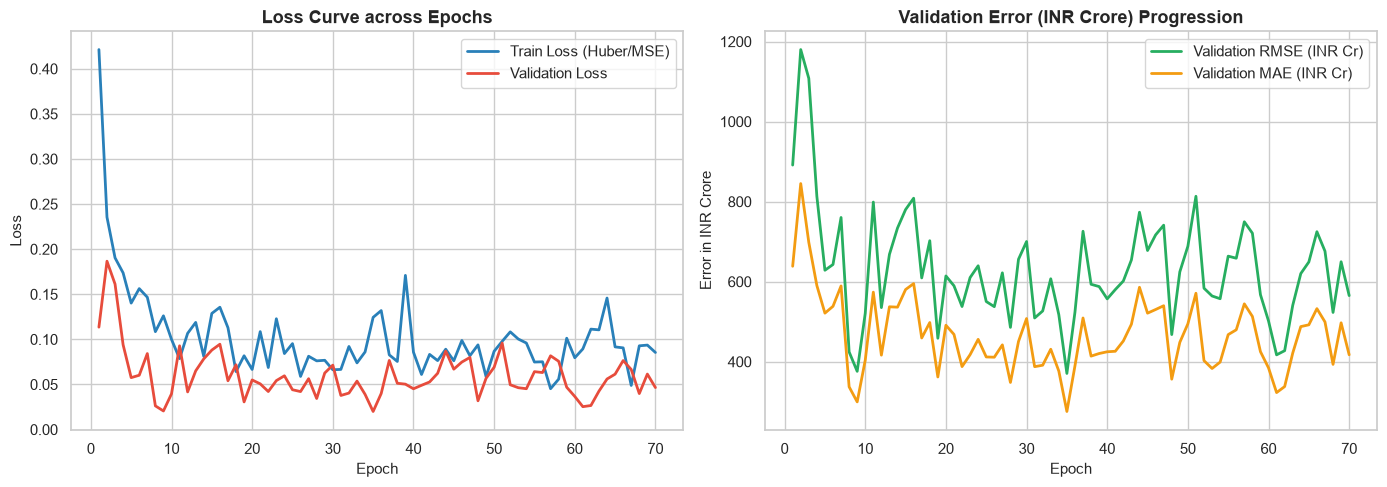

In [6]:
# Plot PyTorch Training Dynamics
fig, (ax1, ax2) = src.plot_training_history(trainer.history)
plt.show()

## 6. Out-of-Time Evaluation & Benchmarking vs Best ML Baseline
We generate unscaled revenue forecasts in INR Crore on the holdout test quarters and benchmark against the best Machine Learning models.

In [7]:
# Generate PyTorch predictions
dl_preds = trainer.predict(X_test)
dl_metrics = src.compute_metrics(y_test.values, dl_preds)

print("=== PYTORCH DEEP LEARNING (4-LAYER MLP) METRICS ===")
for k, v in dl_metrics.items():
    if 'MAPE' in k:
        print(f"{k}: {v:.2f}%")
    elif 'R2' in k:
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v:.2f} Cr")

# Benchmark comparison against ML baseline
from src.models_ml import benchmark_models
ml_benchmark, _, _ = benchmark_models(X_train, y_train, X_test, y_test)

comparison_records = [
    {
        'Model': 'PyTorch Deep MLP (4 Hidden Layers)',
        'Test RMSE': dl_metrics['RMSE'],
        'Test MAE': dl_metrics['MAE'],
        'Test MAPE (%)': dl_metrics['MAPE (%)'],
        'Test R2': dl_metrics['R2'],
        'Architecture': '128-64-32-16 (He Init + BatchNorm + ReLU)'
    },
    {
        'Model': ml_benchmark.iloc[0]['Model'] + ' (Best ML)',
        'Test RMSE': ml_benchmark.iloc[0]['Test RMSE'],
        'Test MAE': ml_benchmark.iloc[0]['Test MAE'],
        'Test MAPE (%)': ml_benchmark.iloc[0]['Test MAPE (%)'],
        'Test R2': ml_benchmark.iloc[0]['Test R2'],
        'Architecture': 'Tree Ensemble / Gradient Boosting'
    }
]

df_dl_compare = pd.DataFrame(comparison_records)
df_dl_compare[['Model', 'Test RMSE', 'Test MAE', 'Test MAPE (%)', 'Test R2', 'Architecture']]

=== PYTORCH DEEP LEARNING (4-LAYER MLP) METRICS ===
MAE: 275.60 Cr
RMSE: 370.68 Cr
MAPE (%): 17.52%
R2: 0.9812
Max Error: 1182.48 Cr


,Model,Test RMSE,Test MAE,Test MAPE (%),Test R2,Architecture
0,PyTorch Deep MLP (4 Hidden Layers),370.682565,275.604386,17.522267,0.981215,128-64-32-16 (He Init + BatchNorm + ReLU)
1,Gradient Boosting (Best ML),241.917237,197.120329,9.780211,0.991999,Tree Ensemble / Gradient Boosting


## 7. Visualizations & Error Diagnostics

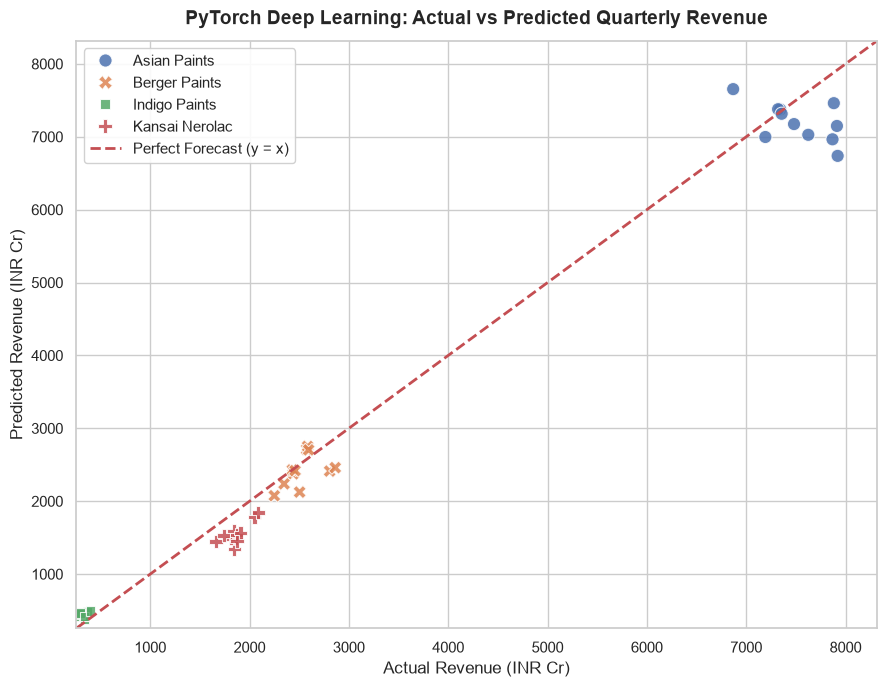

In [8]:
# 1. Actual vs Predicted Scatter Plot
fig, ax = src.plot_actual_vs_predicted(
    y_true=y_test.values,
    y_pred=dl_preds,
    company_labels=clean_qtr.loc[test_mask, 'company'],
    title="PyTorch Deep Learning: Actual vs Predicted Quarterly Revenue"
)
plt.show()

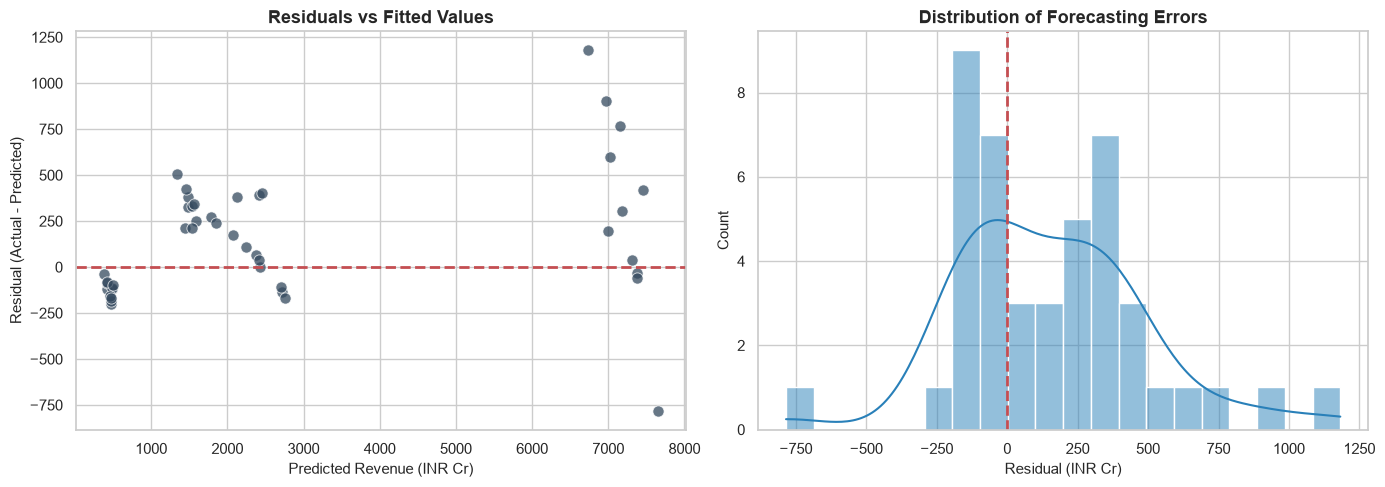

In [9]:
# 2. Residual Diagnostics
fig, (ax1, ax2) = src.plot_residuals(
    y_true=y_test.values,
    y_pred=dl_preds,
    title="PyTorch Deep Learning Residual Diagnostics"
)
plt.show()

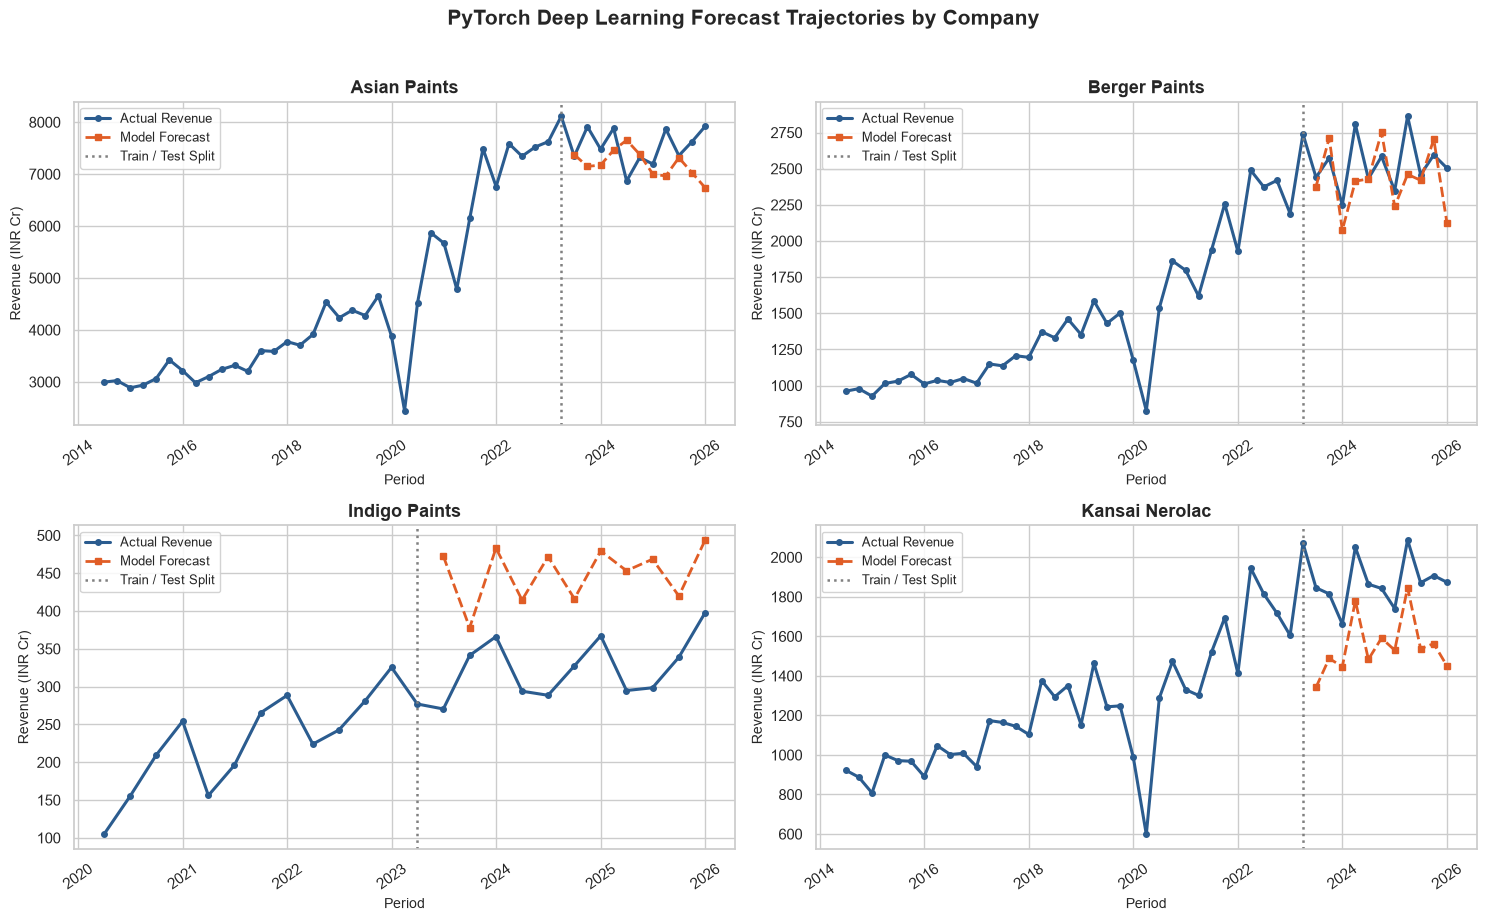

In [10]:
# 3. Quarterly Forecast Trajectories by Company
df_eval_dl = clean_qtr.copy()
df_eval_dl['predicted_revenue'] = np.nan
df_eval_dl.loc[test_mask, 'predicted_revenue'] = dl_preds

fig, axes = src.plot_revenue_trajectories(
    df_eval_dl,
    date_col='period_end',
    actual_col='target_next_revenue',
    pred_col='predicted_revenue',
    company_col='company',
    split_date='2023-03-31',
    title="PyTorch Deep Learning Forecast Trajectories by Company"
)
plt.show()

## 8. Forward Prediction: FY2027 Q1 Revenue Forecast with PyTorch
We feed the latest available FY2026 Q4 operational features into the trained PyTorch network to project **FY2027 Q1 Revenue**.

In [11]:
latest_qtr = df_qtr_feat.groupby('company').tail(1).copy()
X_latest_qtr, _, _, _ = src.prepare_feature_matrix(
    latest_qtr, feature_cols=qtr_feature_cols, target_col="target_next_revenue", drop_na_target=False
)

latest_qtr['pytorch_forecast_FY2027_Q1'] = trainer.predict(X_latest_qtr)
latest_qtr['implied_QoQ_growth_%'] = (
    (latest_qtr['pytorch_forecast_FY2027_Q1'] - latest_qtr['revenue']) / latest_qtr['revenue'] * 100.0
)

print("=== PYTORCH OUT-OF-SAMPLE FY2027 Q1 REVENUE FORECAST (INR CRORE) ===")
latest_qtr[['company', 'financial_year', 'quarter', 'revenue', 'pytorch_forecast_FY2027_Q1', 'implied_QoQ_growth_%']]

=== PYTORCH OUT-OF-SAMPLE FY2027 Q1 REVENUE FORECAST (INR CRORE) ===


,company,financial_year,quarter,revenue,pytorch_forecast_FY2027_Q1,implied_QoQ_growth_%
47,Asian Paints,FY2026,Q4,7920.24,7218.108398,-8.865029
95,Berger Paints,FY2026,Q4,2504.00,2560.130371,2.241628
120,Indigo Paints,FY2026,Q4,397.91,464.586548,16.756691
168,Kansai Nerolac,FY2026,Q4,1873.44,1914.381226,2.185350
